In [ ]:
import os, re, sys, json, time, ast, operator, subprocess
from pathlib import Path
from dataclasses import dataclass, field
import requests
import json
import pandas as pd
import matplotlib.pyplot as plt
from pydantic import BaseModel, Field, ValidationError
from bs4 import BeautifulSoup
from urllib.parse import urlparse

try:
    from dotenv import load_dotenv
    load_dotenv(Path(".env"))
except ImportError:
    pass
try:
    from kaggle_secrets import UserSecretsClient
    os.environ.setdefault("OPENROUTER_API_KEY", UserSecretsClient().get_secret("OPENROUTER_API_KEY"))
except Exception:
    pass
assert os.getenv("OPENROUTER_API_KEY"), "Укажите OPENROUTER_API_KEY в окружении или локальном .env; не сохраняйте ключ в тетрадке"

CHAT_URL = "https://openrouter.ai/api/v1/chat/completions"
HEADERS = {"Authorization": f"Bearer {os.environ['OPENROUTER_API_KEY']}",
           "HTTP-Referer": "https://postypashki.ru", "X-Title": "agents-course-seminar01"}
MODELS = {"cheap": "openai/gpt-4o-mini", "mid": "anthropic/claude-haiku-4.5", "strong": "anthropic/claude-sonnet-4.6"}
COLORS = {"violet": "#5436A3", "amber": "#F09000", "teal": "#00838F", "red": "#C43C3C", "grey": "#787882"}
DATA = Path("data")
DATA.mkdir(exist_ok=True)
TRACES, IMG = Path("traces"), Path("img")
TRACES.mkdir(exist_ok=True)
IMG.mkdir(exist_ok=True)

In [63]:
#  дополнительная часть после прерывания 

Path("interrupted_ledger.json").write_text(
    json.dumps(ledger.calls, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

72732

In [36]:
DATA = Path("data")
dataset_path = DATA / "fresh.jsonl"
assert dataset_path.is_file(), (
    f"Не найден {dataset_path.resolve()}. "
    "Проверьте рабочую папку в Jupyter: Path.cwd()"
)
tasks = [json.loads(line) for line in dataset_path.read_text(encoding="utf-8").splitlines() if line.strip()]
assert tasks, "Файл датасета пуст"
assert len({t["id"] for t in tasks}) == len(tasks), "Повторяющиеся id в датасете"
print(f"Загружено {len(tasks)} вопросов из {dataset_path.resolve()}")
print("Рабочая папка Jupyter:", Path.cwd())

Загружено 145 вопросов из C:\Users\alex-\Documents\AI-agent\pythonProject4\data\fresh.jsonl
Рабочая папка Jupyter: c:\Users\alex-\Documents\AI-agent\pythonProject4


In [37]:
def normalize(text):
    text = re.sub(r"[^\w\s]", " ", str(text).lower().replace(",", ""))
    text = re.sub(r"\b(a|an|the)\b", " ", text)
    return " ".join(text.split())

def is_correct(task, answer):
    if task["source"] == "gsm8k":
        nums = re.findall(r"-?\d+(?:\.\d+)?", str(answer).replace(",", ""))
        return bool(nums) and abs(float(nums[-1]) - float(task["answer"])) < 1e-6
    gold, predicted = normalize(task["answer"]), normalize(answer)
    if not gold:
        return False
    if re.fullmatch(r"\d+(?:\s+\d+)*", gold):
        return bool(re.search(r"(?<!\w)" + re.escape(gold) + r"(?!\w)", predicted))
    return gold in predicted

def summary(config, model, n, correct, cost, steps, seconds=0.0):
    return {"config": config, "model": model.split("/")[-1], "n": n, "accuracy": round(correct / n, 2),
            "cost_per_task": round(cost / n, 5), "cost_per_correct": round(cost / correct, 5) if correct else float("inf"),
            "avg_steps": round(steps, 2), "avg_seconds": round(seconds, 1)}


In [38]:
REQUIRED = ('id','source','question','answer','evidence','url')
def check_dataset(rows):
    problems=[]; ids=set()
    for t in rows:
        missing=[k for k in REQUIRED if not str(t.get(k,'')).strip()]
        if missing: problems.append((t.get('id'),f'нет полей {missing}')); continue
        if t['id'] in ids: problems.append((t['id'],'дублирующийся id'))
        ids.add(t['id'])
        if normalize(t['answer']) not in normalize(t['evidence']):
            problems.append((t['id'],'ответ не содержится в цитате'))
        if len(t['answer']) > 80 or not t['url'].startswith('http'):
            problems.append((t['id'],'длинный ответ или неверный URL'))
        if t['id'].startswith('ai-release-') and t['answer'] not in t['evidence']:
            problems.append((t['id'],'нет буквального вхождения ответа'))
    return problems
problems=check_dataset(tasks)
print('Проблем:',len(problems),problems[:10])
assert not problems

Проблем: 0 []


In [39]:
@dataclass
class Ledger:
    calls: list = field(default_factory=list)

    def add(self, tag, model, usage, seconds=0.0):
        p, c = usage.get("prompt_tokens", 0), usage.get("completion_tokens", 0)
        cost = usage.get("cost") or 0.0
        self.calls.append({"tag": tag, "model": model.split("/")[-1], "prompt": p, "completion": c,
                           "cost": cost, "seconds": round(seconds, 2)})
        return cost

    @property
    def total(self):
        return sum(c["cost"] for c in self.calls)

    def table(self):
        df = pd.DataFrame(self.calls)
        return df.groupby(["tag", "model"]).agg(calls=("cost", "size"), prompt=("prompt", "sum"),
                                                completion=("completion", "sum"), cost=("cost", "sum"),
                                                seconds=("seconds", "sum")).round(5)

ledger = Ledger()

In [40]:
def post_with_retry(body, attempts=3):
    for attempt in range(attempts):
        r = requests.post(CHAT_URL, json=body, headers=HEADERS, timeout=120)
        if r.status_code == 200:
            return r.json()
        if r.status_code in (429, 500, 502, 503) and attempt < attempts - 1:
            time.sleep(1.5 * (attempt+1))
            continue
        raise RuntimeError(f"HTTP {r.status_code} : {r.text[:5000]}")

In [41]:
def chat(messages, model, tools=None, tag="chat", temperature=None):
    if ledger.total - globals().get("SPEND_START_USD", ledger.total) >= globals().get("MAX_NEW_SPEND_USD", float("inf")):
        raise RuntimeError("Достигнут лимит новых расходов. Сохранённые трейсы можно использовать при повторном запуске.")
    body = {"model": model, "messages": messages, "usage": {"include": True}}
    if not tools:
        body["max_tokens"] = 128 
    if tools:
        body["tools"] = tools
        body["tool_choice"] = "auto"
    if temperature is not None:
        body["temperature"] = temperature
    started = time.perf_counter()
    data = post_with_retry(body)
    ledger.add(tag, model, data.get("usage") or {}, time.perf_counter() - started)
    return data["choices"][0]["message"]

In [42]:
TOOLS = {}

def register(fn, args_model, description):
    TOOLS[fn.__name__] = {"fn": fn, "args": args_model, "schema": {"type": "function", "function": {
        "name": fn.__name__, "description": description, "parameters": args_model.model_json_schema()}}}

OPS = {ast.Add: operator.add, ast.Sub: operator.sub, ast.Mult: operator.mul, ast.Div: operator.truediv,
       ast.Pow: operator.pow, ast.USub: operator.neg, ast.Mod: operator.mod}

def evaluate(node):
    if isinstance(node, ast.Constant) and isinstance(node.value, (int, float)):
        return node.value
    if isinstance(node, ast.BinOp) and type(node.op) in OPS:
        return OPS[type(node.op)](evaluate(node.left), evaluate(node.right))
    if isinstance(node, ast.UnaryOp) and type(node.op) in OPS:
        return OPS[type(node.op)](evaluate(node.operand))
    raise ValueError("допустимы только числа и арифметика")

class CalcArgs(BaseModel):
    expr: str = Field(description="арифметическое выражение, например 17*23+5")

def calculator(expr: str) -> str:
    try:
        val = evaluate(ast.parse(expr.replace(",", "."), mode="eval").body)
        return str(int(val)) if float(val).is_integer() else f"{val:.4f}".rstrip("0")
    except Exception as e:
        return f"ошибка вычисления: {e}"

register(calculator, CalcArgs, "Считает арифметическое выражение: числа, скобки, + - * / ** %")
json.dumps(TOOLS["calculator"]["schema"], ensure_ascii=False, indent=1)

'{\n "type": "function",\n "function": {\n  "name": "calculator",\n  "description": "Считает арифметическое выражение: числа, скобки, + - * / ** %",\n  "parameters": {\n   "properties": {\n    "expr": {\n     "description": "арифметическое выражение, например 17*23+5",\n     "title": "Expr",\n     "type": "string"\n    }\n   },\n   "required": [\n    "expr"\n   ],\n   "title": "CalcArgs",\n   "type": "object"\n  }\n }\n}'

In [43]:
SYSTEM = ("Ты решаешь задачи. На вопросы по-русски можешь искать в ru.wikipedia.org (language=ru), затем читать статью с тем же language. Для фактов о новых моделях проверь официальные анонсы через source_search/source_find. Если нужно посчитать или найти факт, вызывай инструменты, а не угадывай. "
          "Когда ответ готов, напиши его последней строкой в формате FINAL: <ответ>. "
          "Для числовых задач в FINAL только число, для вопросов о фактах короткая фраза.")

@dataclass
class Run:
    question: str
    answer: str
    steps: int
    messages: list
    cost: float = 0.0
    seconds: float = 0.0

def looped(seen, calls):
    keys = [(c["function"]["name"], c["function"]["arguments"]) for c in calls]
    repeated = any(k in seen for k in keys)
    seen.update(keys)
    return repeated

def finish(model, messages, step):
    del messages[-1]
    messages.append({"role": "user", "content": "Инструменты больше недоступны. Ответь по тому, что уже известно, последней строкой FINAL: <ответ>."})
    msg = chat(messages, model, tag="agent")
    messages.append(msg)
    return msg.get("content") or "", step + 1

In [44]:
def run_tool(call):
    name = call["function"]["name"]

    try:
        spec = TOOLS[name]
        args = spec["args"].model_validate_json(call["function"]["arguments"])
        result = spec["fn"](**args.model_dump())
    except Exception as e:
        result = f"НЕ удалось вызвать инструмент {name}: {e}"
    return {"role": "tool", "tool_call_id" : call["id"], "content": str(result)[:2000]}

In [45]:
def agent_loop(messages, model, tool_names, max_steps):
    seen = set()
    for step in range(1, max_steps + 1):
        msg = chat(messages, model, tools=[TOOLS[n]["schema"] for n in tool_names] or None, tag='agent')
        messages.append(msg)
        calls = msg.get("tool_calls") or []

        if not calls:
            return msg.get("content") or "", step
        if looped(seen, calls) or step == max_steps:
            return finish(model, messages, step)

        messages += [run_tool(c) for c in calls]


In [46]:
def agent(question, model, tool_names, max_steps=6):
    prompt = SYSTEM if tool_names else "Ответь на вопрос коротко, только строкой FINAL: <ответ>. Если не знаешь, напиши FINAL: unknown. Не объясняй ответ."
    messages = [{"role": "system", "content": prompt}, {"role": "user", "content": question}]
    before, started = ledger.total, time.perf_counter()
    answer, steps = agent_loop(messages, model, tool_names, max_steps)
    return Run(question, answer, steps, messages, ledger.total - before, time.perf_counter() - started)

def show_trace(run):
    for m in run.messages[1:]:
        calls = "; ".join(f"{c['function']['name']}{c['function']['arguments']}" for c in m.get("tool_calls") or [])
        text = " ".join((m.get("content") or "").split())[:180]
        print(f"{m['role']:9s}| {text} {calls}")
    print(f"шагов: {run.steps}, цена: {run.cost * 100:.3f} ¢, время: {run.seconds:.1f} c")

In [15]:
run = agent("Сколько будет 17 * 23 + 5? Посчитай инструментом.", MODELS["cheap"], ["calculator"])
show_trace(run)

user     | Сколько будет 17 * 23 + 5? Посчитай инструментом. 
assistant|  calculator{"expr":"17*23+5"}
tool     | 396 
assistant| FINAL: 396 
шагов: 2, цена: 0.008 ¢, время: 7.3 c


In [47]:
WIKI = "https://en.wikipedia.org/w/api.php"
WIKI_HEADERS = {"User-Agent": "agents-course-seminar01/1.0 (https://postypashki.ru; educational project)"}

def wiki(params, attempts=3, language="en"):
    if language not in ("en", "ru"):
        raise ValueError("Wikipedia language must be en or ru")
    endpoint = f"https://{language}.wikipedia.org/w/api.php"
    for attempt in range(attempts):
        r = requests.get(endpoint, params={**params, "format": "json"}, headers=WIKI_HEADERS, timeout=15)
        if r.status_code == 200 and r.headers.get("content-type", "").startswith("application/json"):
            return r.json()["query"]
        time.sleep(1.0 + attempt)
    raise RuntimeError(f"Википедия ответила {r.status_code}")

class SearchArgs(BaseModel):
    query: str = Field(description="короткий поисковый запрос: имя, название, термин")

class WikiSearchArgs(BaseModel):
    query: str = Field(description="Поисковый запрос: русский для ru, английский для en")
    language: str = Field(default="en", description="Язык Википедии: en или ru")

class ExecArgs(BaseModel):
    code: str = Field(description="код на Python; результат надо напечатать через print")

In [48]:
def web_search(query: str, language: str = "en") -> str:
    hits = wiki({'action':'query','list':'search','srsearch':query,'srlimit':3}, language=language)['search']
    if not hits: return 'No data'
    title=hits[0]['title']
    pages=wiki({'action':'query','prop':'extracts','explaintext':1,'exintro':1,'titles':title}, language=language)['pages']
    text=' '.join(next(iter(pages.values())).get('extract','').split())
    return f'[{language}:{title}] {text[:3500]} | Other titles: {[h["title"] for h in hits[1:]]}'

In [49]:
def page_find(title: str, keywords: str, language: str = "en") -> str:
    pages=wiki({'action':'query','prop':'extracts','explaintext':1,'titles':title}, language=language)['pages']
    full=next(iter(pages.values())).get('extract','')
    terms=[w.lower() for w in keywords.split() if len(w)>1]
    lines=[line.strip() for line in full.splitlines() if any(w in line.lower() for w in terms)]
    return '\n'.join(lines[:18])[:6500] if lines else 'No matching lines'

In [50]:
class FindArgs(BaseModel):
    title: str = Field(description='Точный заголовок статьи из web_search')
    keywords: str = Field(description='Ключевые слова на языке статьи: модель, дата, технический термин')
    language: str = Field(default='en', description='Язык статьи: en или ru; тот же, что использован в web_search')

In [51]:
ALLOWED_DOMAINS=('openai.com','anthropic.com','blog.google','ai.meta.com','wikipedia.org')

def allowed_url(url):
    u=urlparse(url)
    return u.scheme=='https' and any(u.hostname == host or u.hostname.endswith('.'+host) for host in ALLOWED_DOMAINS)

In [52]:
def source_search(query: str) -> str:
    r=requests.get('https://www.google.com/search',params={'q':query+' site:openai.com OR site:anthropic.com OR site:blog.google OR site:ai.meta.com'},headers={'User-Agent':'Mozilla/5.0'},timeout=15)
    r.raise_for_status()
    soup=BeautifulSoup(r.text,'html.parser')
    hits=[]
    for a in soup.select('a[href]'):
        href=a.get('href','')
        if href.startswith('/url?'): 
            from urllib.parse import parse_qs
            href=parse_qs(urlparse(href).query).get('q',[''])[0]
        if allowed_url(href) and href not in [x['url'] for x in hits]:
            hits.append({'title':a.get_text(' ',strip=True)[:120],'url':href})
        if len(hits)>=6: break
    return json.dumps(hits,ensure_ascii=False) if hits else 'No data'

In [53]:
def source_find(url: str, keywords: str) -> str:
    if not allowed_url(url): return 'Unsupported domain or URL'
    r=requests.get(url,headers={'User-Agent':'Mozilla/5.0'},timeout=20)
    r.raise_for_status()
    soup=BeautifulSoup(r.text,'html.parser')
    for tag in soup(['script','style','nav','footer']): tag.decompose()
    paragraphs=[p.get_text(' ',strip=True) for p in soup.select('p, li, h1, h2, h3')]
    terms=[w.lower() for w in keywords.split() if len(w)>1]
    lines=[p[:900] for p in paragraphs if any(w in p.lower() for w in terms)]
    return '\n'.join(lines[:14])[:6500] if lines else 'No matching lines'

In [54]:
class URLArgs(BaseModel):
    url: str = Field(description='https URL returned by source_search on an official developer website')
    keywords: str = Field(description='Distinctive model name, release term, or date')

In [55]:
def python_exec(code: str) -> str:
    try:
        r = subprocess.run([sys.executable, "-I", "-c", code], capture_output=True, text=True, timeout=5)
    except subprocess.TimeoutExpired:
        return "Код превысил 5 сек"
    out = (r.stdout + r.stderr).strip()
    return out[:5000] if out else "Код исполнился но результат пустой"

In [56]:
register(web_search, WikiSearchArgs, 'Searches English or Russian Wikipedia. For Russian questions try language=ru; for English try en. Returns article titles and introduction.')
register(page_find, FindArgs, 'Reads FULL Wikipedia article in language en or ru. Pass the same language as web_search and keywords in that language.')
register(source_search, SearchArgs, 'Finds official AI release URLs on OpenAI, Anthropic, Google and Meta websites using a second web search source.')
register(source_find, URLArgs, 'Reads an official AI release page and returns paragraphs matching keywords.')
register(python_exec, ExecArgs, 'Runs short Python code separately and returns printed output.')
assert calculator('2+2') == '4'
assert 'ошибка' in calculator('__import__("os")')


## Тестирование инструментов

чтобы соответствовать критерию: у каждого инструмента тест на три случая: нормальный вход, пустой результат, ошибка;

In [57]:
from unittest.mock import patch, Mock
with patch('requests.get') as get:
    get.return_value=Mock(status_code=200,headers={'content-type':'application/json'})
    get.return_value.json.side_effect=[{'query':{'search':[{'title':'2026 in science'}]}},
                                        {'query':{'pages':{'1':{'extract':'Fact in introduction'}}}}]
    assert 'Fact in introduction' in web_search('science')
with patch('requests.get') as get:
    get.return_value=Mock(status_code=200,headers={'content-type':'application/json'})
    get.return_value.json.return_value={'query':{'search':[]}}
    assert web_search('nonexistent')=='No data'
with patch('requests.get',side_effect=requests.ConnectionError('offline')):
    try: web_search('science'); assert False
    except requests.ConnectionError: pass
with patch('requests.get') as get:
    get.return_value=Mock(status_code=200,headers={'content-type':'application/json'})
    get.return_value.json.return_value={'query':{'pages':{'1':{'extract':'hello\nAI model launched today'}}}}
    assert 'launched' in page_find('2026 in science','launched')
    assert page_find('2026 in science','nothinghere')=='No matching lines'
with patch('requests.get',side_effect=requests.ConnectionError('offline')):
    try: page_find('test','word'); assert False
    except requests.ConnectionError: pass
with patch('requests.get') as get:
    get.return_value=Mock(text='<a href="https://openai.com/index/release">Official release</a>')
    assert 'openai.com' in source_search('release')
    get.return_value=Mock(text='<html><body>Nothing</body></html>')
    assert source_search('unknown')=='No data'
with patch('requests.get',side_effect=requests.ConnectionError('offline')):
    try: source_search('release'); assert False
    except requests.ConnectionError: pass
with patch('requests.get') as get:
    get.return_value=Mock(text='<p>New model released in 2026</p>')
    assert 'released' in source_find('https://openai.com/index/release','released')
    assert source_find('https://openai.com/index/release','none')=='No matching lines'
with patch('requests.get',side_effect=requests.ConnectionError('offline')):
    try: source_find('https://openai.com/index/release','released'); assert False
    except requests.ConnectionError: pass
assert calculator('2*3')=='6'
assert 'ошибка' in calculator('')
assert 'ошибка' in calculator('1/0')
assert python_exec('print(2+2)')=='4'
assert 'пустой' in python_exec('pass')
assert 'ZeroDivisionError' in python_exec('1/0')
# Проверяем оба языка на уровне URL, без сетевых вызовов.
with patch('requests.get') as get:
    get.return_value=Mock(status_code=200,headers={'content-type':'application/json'})
    get.return_value.json.side_effect=[{'query':{'search':[{'title':'Искусственный интеллект'}]}},
                                        {'query':{'pages':{'1':{'extract':'Новая модель'}}}}]
    assert 'Новая модель' in web_search('новая модель',language='ru')
    assert all('ru.wikipedia.org' in call.args[0] for call in get.call_args_list)
with patch('requests.get') as get:
    get.return_value=Mock(status_code=200,headers={'content-type':'application/json'})
    get.return_value.json.return_value={'query':{'pages':{'1':{'extract':'Новая модель выпущена в 2026 году'}}}}
    assert 'выпущена' in page_find('Искусственный интеллект','выпущена',language='ru')
    assert 'ru.wikipedia.org' in get.call_args.args[0]
try:
    wiki({'action':'query'}, language='xx')
    assert False
except ValueError:
    pass
print('5 инструментов × 3 сценария и поиск ru/en: успешно')

5 инструментов × 3 сценария и поиск ru/en: успешно


In [58]:
def final_answer(text):
    m = re.search(r"FINAL:\s*(.+)", text or "")
    return m.group(1).strip() if m else (text or "").strip()

In [59]:
def run_tasks(tasks, model, tool_names, config):
    folder = TRACES / config / model.split("/")[-1]
    folder.mkdir(parents=True, exist_ok=True)
    checkpoints = Path("checkpoints")
    checkpoints.mkdir(exist_ok=True)
    checkpoint = checkpoints / f"{config}__{model.split('/')[-1]}.csv"
    rows = []
    cached_count = 0
    for task in tasks:
        path = folder / f"{task['id']}.json"
        cached = None
        if path.is_file():
            try:
                previous = json.loads(path.read_text(encoding="utf-8"))
                old_task = previous.get("task", {})
                if (old_task.get("id"), old_task.get("question"), old_task.get("answer")) != (task["id"], task["question"], task["answer"]):
                    raise ValueError(f"Трейс {path} создан для другого вопроса/эталона. Уберите его вручную или смените id.")
                if previous.get("messages") and not str(previous.get("answer", "")).startswith("ошибка:"):
                    cached = previous
            except (json.JSONDecodeError, UnicodeError):
                pass  
        if cached is not None:
            cached_count += 1
            messages = cached["messages"]
            answer = cached["answer"]
            steps = cached.get("steps", sum(m.get("role") == "assistant" for m in messages))
            tool_calls = sum(m.get("role") == "tool" for m in messages)
            cost = cached["cost"]
            seconds = cached.get("seconds", float("nan"))
        else:
            run = agent(task["question"], model, tool_names)
            answer, messages, steps, cost, seconds = run.answer, run.messages, run.steps, run.cost, run.seconds
            tool_calls = sum(m.get("role") == "tool" for m in messages)
            record = {"task": task, "answer": answer, "correct": is_correct(task, final_answer(answer)),
                      "cost": cost, "seconds": seconds, "steps": steps, "messages": messages}
            tmp = path.with_suffix(".json.tmp")
            tmp.write_text(json.dumps(record, ensure_ascii=False, indent=1), encoding="utf-8")
            tmp.replace(path)
        rows.append({"config": config, "model": model.split("/")[-1], "id": task["id"], "source": task["source"],
                     "correct": is_correct(task, final_answer(answer)), "steps": steps, "tool_calls": tool_calls,
                     "cost": cost, "seconds": seconds, "answer": final_answer(answer)[:60], "gold": task["answer"]})
        pd.DataFrame(rows).to_csv(checkpoint, index=False)
    print(f"{config}: {len(rows)}/{len(tasks)}; восстановлено из трейсов {cached_count}; новых расходов в ядре ${ledger.total-SPEND_START_USD:.3f}")
    return pd.DataFrame(rows)

In [60]:
def report(results):
    rows = [summary(config, model, len(df), int(df["correct"].sum()), df["cost"].sum(), df["steps"].mean(), df["seconds"].mean())
            for (config, model), df in results.groupby(["config", "model"])]
    table = pd.DataFrame(rows).sort_values("cost_per_task").reset_index(drop=True)
    missing = results.groupby(["config", "model"])["seconds"].apply(lambda x: x.isna().any())
    for i, row in table.iterrows():
        if missing.loc[(row["config"], row["model"])]:
            table.loc[i, "avg_seconds"] = float("nan")
    return table

def money_chart(table, path="img/money_quality.png"):
    fig, ax = plt.subplots(figsize=(8, 5))
    for _, r in table.iterrows():
        color = COLORS["red"] if "каскад" in r["config"] else COLORS["amber"] if "sonnet" in r["model"] else COLORS["violet"]
        ax.scatter(r["cost_per_task"] * 100, r["accuracy"] * 100, s=110, color=color)
        ax.annotate(f"{r['config']}\n{r['model']}", (r["cost_per_task"] * 100, r["accuracy"] * 100),
                    fontsize=8, xytext=(6, 4), textcoords="offset points")
    ax.set_xscale("log")
    ax.set_xlabel("цена задачи, центы (логарифмическая шкала)")
    ax.set_ylabel("доля верных ответов, %")
    ax.grid(alpha=0.3)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    return fig

In [70]:
MAX_NEW_SPEND_USD = 0.75  
SPEND_START_USD = ledger.total
print(f"Дополнительный лимит: ${MAX_NEW_SPEND_USD:.2f}; уже потрачено в этом ядре: ${ledger.total:.3f}")

Дополнительный лимит: $0.75; уже потрачено в этом ядре: $2.255


дешёвая без инструментов: 145/145; восстановлено из трейсов 145; новых расходов в ядре $0.000
дешёвая только поиск: 145/145; восстановлено из трейсов 145; новых расходов в ядре $0.000
дешёвая поиск и чтение: 145/145; восстановлено из трейсов 145; новых расходов в ядре $0.000
средняя поиск и чтение: 145/145; восстановлено из трейсов 144; новых расходов в ядре $0.014
сильная без инструментов: 145/145; восстановлено из трейсов 45; новых расходов в ядре $0.056


,config,model,n,accuracy,cost_per_task,cost_per_correct,avg_steps,avg_seconds
0,дешёвая без инструментов,gpt-4o-mini,145,0.00,0.00001,inf,1.00,3.0
1,дешёвая только поиск,gpt-4o-mini,145,0.16,0.00053,0.00336,4.48,25.2
2,дешёвая поиск и чтение,gpt-4o-mini,145,0.19,0.00073,0.00393,4.92,26.0
3,сильная без инструментов,claude-sonnet-4.6,145,0.03,0.00488,0.14160,1.00,NaN
4,средняя поиск и чтение,claude-haiku-4.5,145,0.41,0.01412,0.03412,3.70,23.4


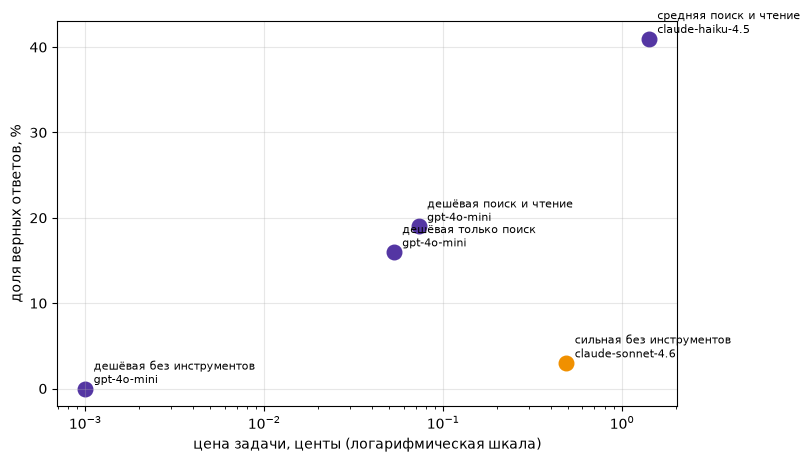

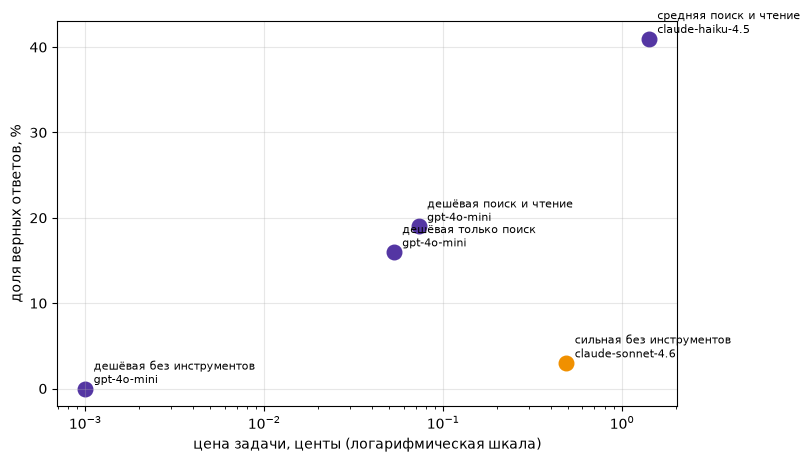

In [71]:
frames=[run_tasks(tasks,MODELS['cheap'],[],'дешёвая без инструментов')]
frames.append(run_tasks(tasks,MODELS['cheap'],['web_search','source_search'],'дешёвая только поиск'))
frames.append(run_tasks(tasks,MODELS['cheap'],['web_search','page_find','source_search','source_find','calculator','python_exec'],'дешёвая поиск и чтение'))
frames.append(run_tasks(tasks,MODELS['mid'],['web_search','page_find','source_search','source_find','calculator','python_exec'],'средняя поиск и чтение'))
frames.append(run_tasks(tasks,MODELS['strong'],[],'сильная без инструментов'))
results=pd.concat(frames,ignore_index=True)
table=report(results)
display(table)
results.to_csv('results.csv',index=False)
table.to_csv('report.csv',index=False)
money_chart(table,path=str(IMG/'money_chart.png'))

In [75]:
results["cost"].sum()

np.float64(2.9403558500000004)

In [72]:
bad = results[
    (results["config"] == "дешёвая поиск и чтение")
    & (~results["correct"])
]
display(bad[["id", "answer", "gold", "steps", "cost"]].head(10))

,id,answer,gold,steps,cost
290,fresh-0,"March 15, 2026",15 March,5,0.000806
291,fresh-1,"March 22, 2026",22 March,6,0.000858
292,fresh-2,Иран.,Miguel Díaz-Canel,7,0.001505
293,fresh-3,Информация отсутствует.,a strategic partnership agreement,5,0.000660
294,fresh-4,информация недоступна.,A total fire ban,7,0.001008
295,fresh-5,2,two people,2,0.000222
296,fresh-6,519,"4,500",2,0.000258
297,fresh-7,Информация отсутствует.,Deniz Göktaş,7,0.000967
298,fresh-8,информация недоступна.,Pavel Durov,7,0.000917
300,fresh-10,Неизвестно.,Twelve,7,0.000975


In [79]:
question_id = "fresh-2"

trace_path = Path("traces") / "дешёвая поиск и чтение" / "gpt-4o-mini" / f"{question_id}.json"
trace = json.loads(trace_path.read_text(encoding="utf-8"))

print("Вопрос:", trace["task"]["question"])
print("Эталон:", trace["task"]["answer"])
print("Ответ агента:", trace["answer"])

for message in trace["messages"]:
    print(message["role"], message.get("tool_calls") or "",
          str(message.get("content") or "")[:1500])

Вопрос: Who entered negotiations with the Trump administration on March 13, 2026?
Эталон: Miguel Díaz-Canel
Ответ агента: На 13 марта 2026 года в переговоры с администрацией Трампа вступила Иранская сторона. FINAL: Иран.
system  Ты решаешь задачи. На вопросы по-русски можешь искать в ru.wikipedia.org (language=ru), затем читать статью с тем же language. Для фактов о новых моделях проверь официальные анонсы через source_search/source_find. Если нужно посчитать или найти факт, вызывай инструменты, а не угадывай. Когда ответ готов, напиши его последней строкой в формате FINAL: <ответ>. Для числовых задач в FINAL только число, для вопросов о фактах короткая фраза.
user  Who entered negotiations with the Trump administration on March 13, 2026?
assistant [{'type': 'function', 'index': 0, 'id': 'call_3G7hMA6Ri6fPJ72asFltrr6E', 'function': {'name': 'web_search', 'arguments': '{"query":"negotiations Trump administration March 13 2026","language":"en"}'}}] 
tool  [en:2025–2026 Iran–United States

In [73]:
bad = results[
    (results["config"] == "средняя поиск и чтение")
    & (~results["correct"])
]
display(bad[["id", "answer", "gold", "steps", "cost"]].head(10))

,id,answer,gold,steps,cost
437,fresh-2,I don't have access to information about event...,Miguel Díaz-Canel,1,0.003005
440,fresh-5,2,two people,2,0.006109
441,fresh-6,519 people are reported missing in the Tibet A...,"4,500",2,0.006442
442,fresh-7,I don't have access to information about event...,Deniz Göktaş,1,0.003109
443,fresh-8,I don't have access to information about event...,Pavel Durov,1,0.003017
445,fresh-10,Мне не удалось найти конкретную информацию о в...,Twelve,7,0.022828
447,fresh-12,"К сожалению, я не смог найти конкретные данные...","700,000",7,0.028234
448,fresh-13,I don't have access to information about 2026 ...,41.5 °C,1,0.003269
449,fresh-14,I'm not finding specific information about thi...,Ciudad Rodrigo,5,0.018759
452,fresh-17,"I apologize, but I'm unable to find specific i...",EOS-05,5,0.018381


In [74]:
bad = results[
    (results["config"] == "сильная без инструментов")
    & (~results["correct"])
]
display(bad[["id", "answer", "gold", "steps", "cost"]].head(10))

,id,answer,gold,steps,cost
580,fresh-0,"March 15, 2026",15 March,1,0.008445
581,fresh-1,"February 27, 2025",22 March,1,0.002040
582,fresh-2,Ukraine (and Russia) entered negotiations with...,Miguel Díaz-Canel,1,0.010851
583,fresh-3,Ukraine and Romania signed an agreement on mil...,a strategic partnership agreement,1,0.006942
584,fresh-4,Minimum energy efficiency standards for rental...,A total fire ban,1,0.041118
585,fresh-5,1,two people,1,0.003375
586,fresh-6,I don't have information about floods in Tibet...,"4,500",1,0.004464
587,fresh-7,I don't have verified information about this s...,Deniz Göktaş,1,0.005148
588,fresh-8,"I don't have information about this event, as ...",Pavel Durov,1,0.003837
589,fresh-9,Zhengzhou,New Delhi,1,0.002949
